# DNAscape simulation atlas (`rsim`)

This notebook introduces `rsim`, the DNAscape workflow for stochastic simulation of DNA replication. Given supplied kinetic inputs, such as an origin firing-rate profile and fork speed, together with modelling assumptions such as genomic resolution, geometry, stalling, and finite firing-factor constraints, `rsim` generates simulated S phases from which replication features can be measured.

Whereas `rmap` maps between replication features through deterministic or fitted relationships, `rsim` acts as a simulation-based feature generator. It can produce quantities such as replication timing, fork directionality, replicated fraction, completion time, origin efficiency, and fork density, which can then be compared with theoretical predictions from `rmap`.

The main link between the two workflows is the shared `source` and `assumptions` interface introduced in `2-mapping.ipynb`. A typical analysis first uses `rmap` to infer kinetic inputs, for example a firing-rate profile from replication timing and fork speed, and then passes those inputs to `rsim` to simulate replication dynamics under the same assumptions. The connection also works in the opposite direction, since some `rmap` targets use simulation-based routes and call `rsim` internally.

Throughout this notebook, `source` contains the supplied biological or kinetic quantities, most often `firing_rate` and `fork_speed`. `assumptions` contains the modelling and numerical choices that define the simulation, including genomic resolution, number of simulated S phases, random seed, geometry, time grid, stalling, and finite firing-factor settings.

## What `rsim` Can Return

The simulator returns a dictionary. The exact values requested depend on the assumptions, but the source code groups naturally into these output families:

1. **Spatial profiles:** `replication_timing`, `origin_efficiency`/`efficiency`, and `fork_directionality`.
2. **Per-simulation summaries:** `rep_times_per_sim`, `completion_time`/`s_phase_duration`, `num_origins`/`num_oris`, and `inter_origin_distance`/`inter_origin_distances`.
3. **Time courses:** `time_grid`, `dt_grid`, `replicated_fraction`, `total_forks`, `active_forks`, `stalled_forks`, and, when finite firing factors are enabled, `firing_factors`.
4. **Space-time fields:** with `time_stats_xtQ=True`, `replicated_fraction_xt`, `initiation_events_xt`, `coalescence_events_xt`, `right_fork_density_xt` and `left_fork_density_xt`. These fields are position-by-time matrices, so `field[i]` is the time trace at genomic position `i`. A total fork-density field can be formed by summing the right- and left-moving fork-density fields.

The notebook is organized in the same order: first one timing result, then the richer feature atlas.


## Table of Contents

1. Setup
2. Build one simulation input with `rmap`
3. Single simulation: timing only
4. Larger ensemble: feature atlas input
5. Spatial feature profiles
6. Per-simulation feature distributions
7. Time-course features
8. Space-time feature fields
9. Optional mechanisms and `rmap` routes


## 1. Setup

Load the DNAscape public interface. Autoreload keeps the notebook aligned with local package edits while developing the simulation API and examples.


In [10]:
%reload_ext autoreload
%autoreload 2

from dnascape import *


## 2. Single simulation

### 2.1 Select a genomic region and infer a firing-rate profile

We start from replication timing data, choose chromosome 1, set a 1 kb spatial resolution, and select the first 60 Mb. The firing-rate profile is inferred with `rmap(target="firing_rate")` under a constant fork-speed assumption.

This is the bridge from mapping to simulation: `2-mapping.ipynb` explains how the kinetic feature is inferred, while this notebook asks what stochastic replication dynamics that kinetic feature can generate.


In [11]:
chr_number = 1
output_resolution_kb = 1
interval_kb = (0, 60_000)
fork_speed = 1.4

replication_timing_full = loadcsv("example", example="replication_timing_hESC", chr_number=chr_number)
replication_timing, positions_kb = select_profile_region(
    replication_timing_full,
    output_resolution_kb=output_resolution_kb,
    interval_kb=interval_kb,
)

firing_rate = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={"resolution_x": output_resolution_kb, "maxiter": 6},
)


## 3. Single Simulation: Timing Only

### 3.1 Run one stochastic S phase

Before using the simulator as a feature generator, it helps to see the simplest possible object. Here `sim_number=1` runs one stochastic realization from the inferred firing-rate landscape. We intentionally do not request time courses or space-time statistics in this first call.


In [16]:
single_simulation = rsim(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 1,
        "resolution_x": output_resolution_kb,
    },
)


### 3.2 Inspect only the timing profile

The first output is `single_simulation["replication_timing"]`: the replication time assigned to each genomic bin in that one simulated S phase. It is noisier than an ensemble mean because it is one realization, not a population average.


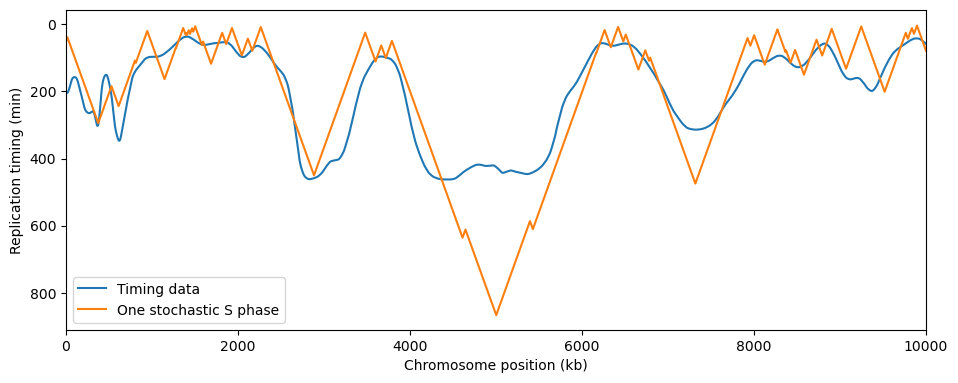

In [14]:
plotf(
    replication_timing,
    single_simulation["replication_timing"],
    x_array=positions_kb,
    labels=["Timing data", "One stochastic S phase"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
    xlims=(0,10000)
)


## 4. Larger Ensemble: Feature Atlas Input

### 4.1 Run many stochastic S phases

Now we increase `sim_number` and request `time_statsQ=True`. This turns one simulation call into an ensemble summary: spatial profiles are averaged across S phases, per-simulation summaries are retained, and one-dimensional time courses are calculated on `time_grid`.

This is the main object used in the rest of the notebook.


In [15]:
sim_number = 200
time_grid = np.arange(0.0, 800.0 + 1.0, 1.0)

simulation = rsim(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": sim_number,
        "resolution_x": output_resolution_kb,
        "time_statsQ": True,
        "time_grid": time_grid,
    },
)


### 4.2 List the available features

The dictionary includes all possible keys, but some values are `None` unless the corresponding statistics were requested. Listing the non-empty keys is a quick way to see what this particular run can support.


In [17]:
available_features = sorted(key for key, value in simulation.items() if value is not None)
available_features


['active_forks',
 'completion_time',
 'dt_grid',
 'efficiency',
 'fork_directionality',
 'inter_origin_distance',
 'inter_origin_distances',
 'num_origins',
 'num_oris',
 'origin_efficiency',
 'rep_times_per_sim',
 'replicated_fraction',
 'replication_timing',
 's_phase_duration',
 'stalled_forks',
 'time_grid',
 'total_forks']

## 5. Spatial Feature Profiles

Spatial profiles have one value per genomic bin. They are the easiest way to compare the input timing profile, inferred kinetics, and simulation-derived observables along the same chromosome coordinate.


### 5.1 Mean replication timing

`simulation["replication_timing"]` is the ensemble mean replication time at each position. Comparing it with both the original timing data and the single stochastic S phase shows how individual simulation noise collapses into a stable population-level profile.


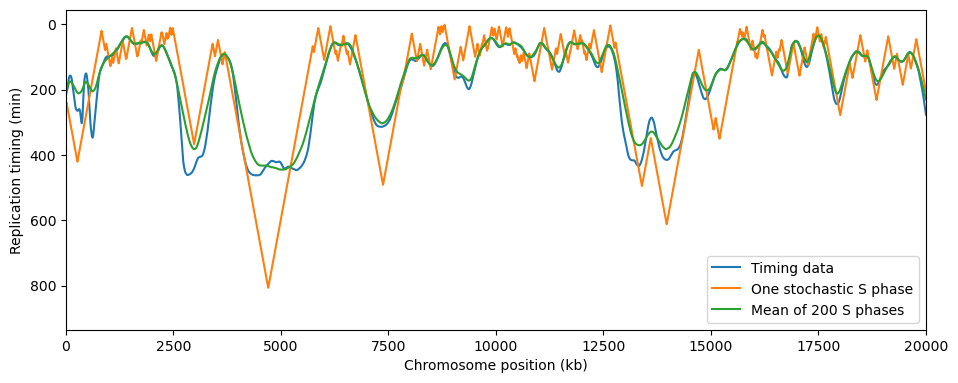

In [20]:
plotf(
    replication_timing,
    single_simulation["replication_timing"],
    simulation["replication_timing"],
    x_array=positions_kb,
    labels=["Timing data", "One stochastic S phase", f"Mean of {sim_number} S phases"],
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
    xlims=(0,20000)
)


### 5.2 Origin efficiency

`origin_efficiency` records how often each genomic bin fired as an origin across the ensemble. It is not the same as the input firing-rate landscape: efficient origins are those that fire before they are passively replicated by forks from neighboring origins.


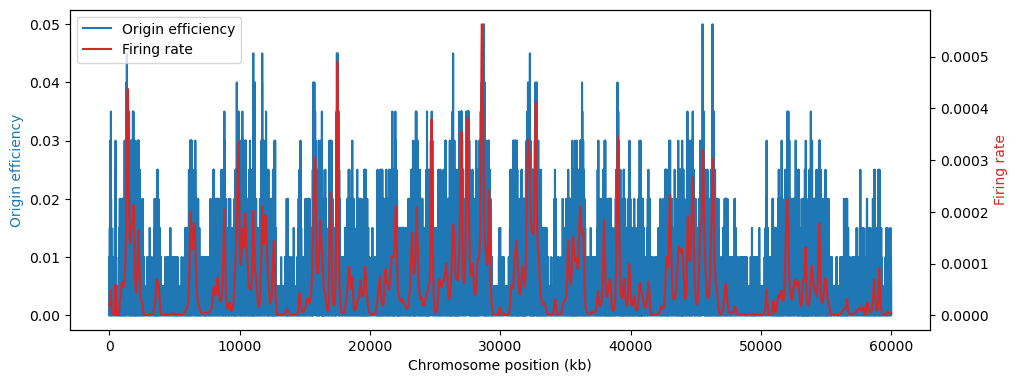

In [21]:
plotf(
    simulation["origin_efficiency"],
    firing_rate,
    x_array=positions_kb,
    labels=["Origin efficiency", "Firing rate"],
    dual_axis=True,
    xtitle="Chromosome position (kb)",
)


### 5.3 Fork directionality

`fork_directionality` is the average direction from which each position was replicated. Values near +1 indicate predominantly right-moving forks, values near -1 indicate predominantly left-moving forks, and values near 0 indicate a balance across the ensemble.


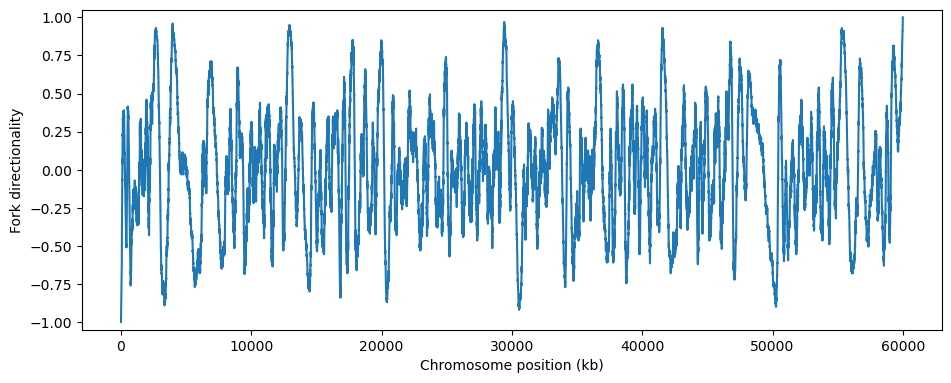

In [22]:
plotf(
    simulation["fork_directionality"],
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Fork directionality",
    ylims=(-1.05, 1.05),
)


## 6. Per-Simulation Feature Distributions

Some outputs summarize whole simulated S phases rather than individual genomic bins. These are useful when the variability across cells is part of the biological question.


### 6.1 Local timing variability

`rep_times_per_sim` stores the replication-time profile for every simulated S phase. Taking the standard deviation across simulations gives a spatial map of timing variability, which is lost if we only inspect the mean timing curve.


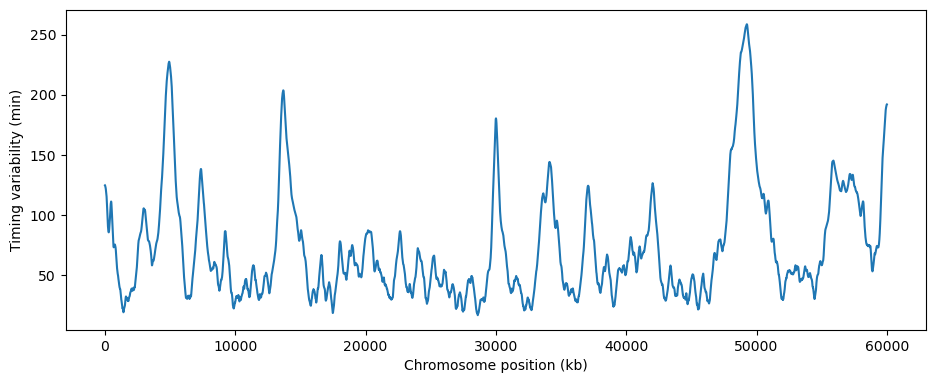

In [23]:
rep_times = np.asarray(simulation["rep_times_per_sim"], dtype=float)
rep_times[~np.isfinite(rep_times)] = np.nan
replication_timing_std = np.nanstd(rep_times, axis=0)

plotf(
    replication_timing_std,
    x_array=positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Timing variability (min)",
)


### 6.2 Completion time and origin count

`completion_time` is the simulated S-phase duration for each realization. `num_origins` records how many origins fired in each realization. Together they show whether faster completion is associated with more initiation events under the current kinetic landscape.


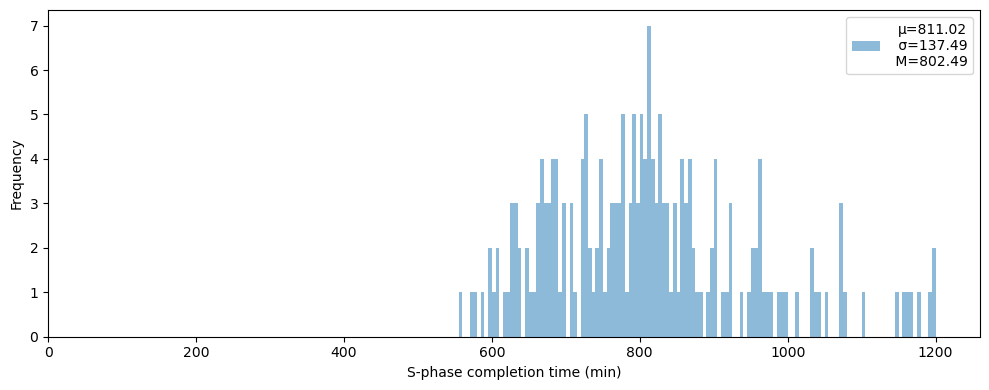

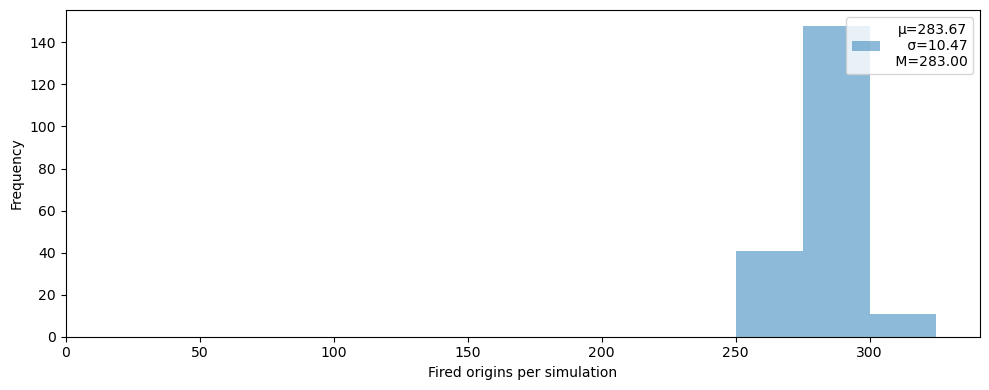

In [24]:
ploth(
    simulation["completion_time"],
    xtitle="S-phase completion time (min)",
    bin_size=5,
)

ploth(
    simulation["num_origins"],
    xtitle="Fired origins per simulation",
    bin_size=25,
)


### 6.3 Inter-origin distances

`inter_origin_distance` pools distances between neighboring fired origins across all realizations. It is a compact single-molecule-like summary of how densely the replication programme initiates.


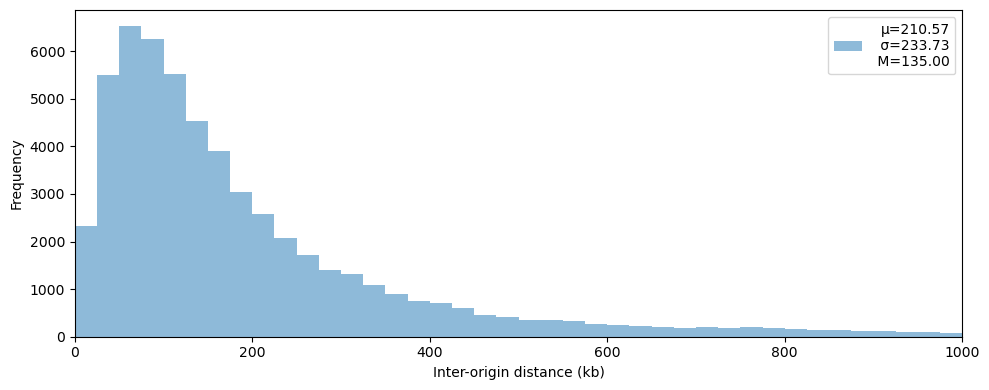

In [25]:
ploth(
    simulation["inter_origin_distance"],
    xtitle="Inter-origin distance (kb)",
    bin_size=25,
    xmax=1000,
)


## 7. Time-Course Features

With `time_statsQ=True`, `rsim` returns one-dimensional time courses. These collapse over genomic position and describe how replication progresses through S phase.


### 7.1 Replicated fraction

`replicated_fraction` is the fraction of the simulated region that has replicated by each time point in `time_grid`. It is the simulated counterpart of a population-level S-phase progression curve.


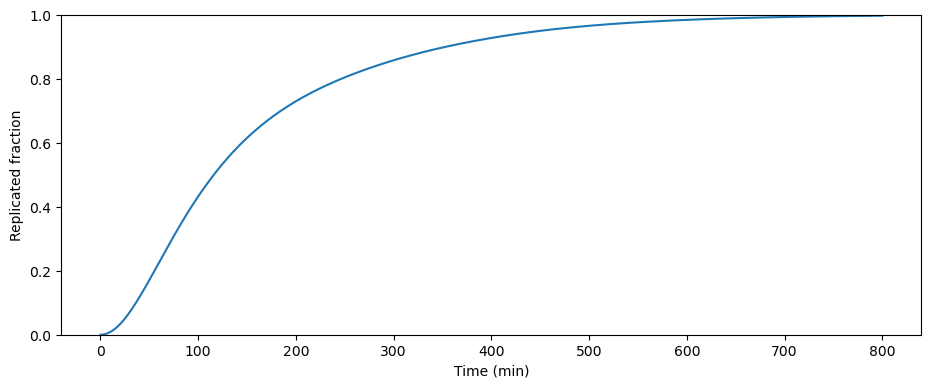

In [26]:
plotf(
    simulation["replicated_fraction"],
    x_array=simulation["time_grid"],
    xtitle="Time (min)",
    ytitle="Replicated fraction",
    ylims=(0, 1),
)


### 7.2 Fork counts

`total_forks` counts all forks present at each time point, `active_forks` removes stalled forks, and `stalled_forks` reports the stalled subset. Without stalling, the stalled curve should remain at zero.


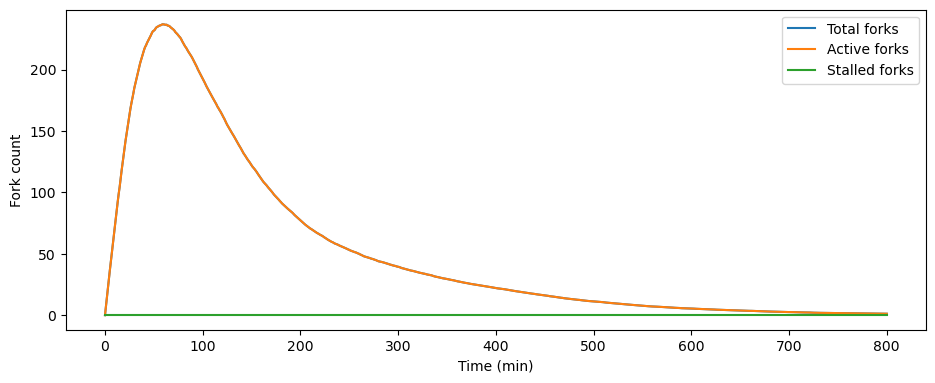

In [27]:
plotf(
    simulation["total_forks"],
    simulation["active_forks"],
    simulation["stalled_forks"],
    x_array=simulation["time_grid"],
    labels=["Total forks", "Active forks", "Stalled forks"],
    xtitle="Time (min)",
    ytitle="Fork count",
)


## 8. Space-Time Feature Fields

Space-time outputs are more expensive because they keep a value for every time point and genomic bin. To keep this example lightweight, we run a smaller 5 Mb showcase region with `time_stats_xtQ=True`.


In [28]:
showcase_length_kb = 5_000
showcase_n = int(showcase_length_kb / output_resolution_kb)
showcase_positions_kb = positions_kb[:showcase_n]
showcase_firing_rate = firing_rate[:showcase_n]
showcase_time_grid = np.arange(0.0, 500.0 + 5.0, 5.0)

xt_simulation = rsim(
    source={
        "firing_rate": showcase_firing_rate,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 25,
        "resolution_x": output_resolution_kb,
        "seed": 2,
        "time_statsQ": True,
        "time_stats_xtQ": True,
        "time_grid": showcase_time_grid,
        "dens_block_n": 1024,
        "verbose": False,
    },
)


### 8.1 Replicated fraction in space and time

`replicated_fraction_xt` shows the local probability of being replicated as a function of genomic position and time. This is the most direct simulation analogue of a full replication-progression field.


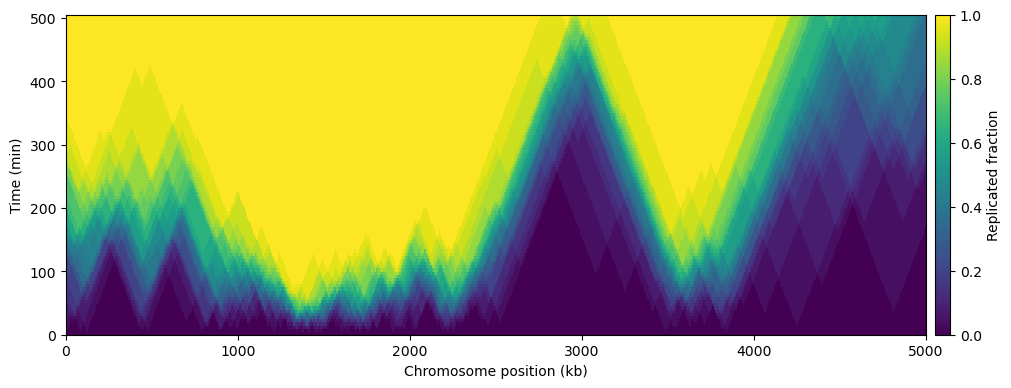

In [29]:
plotf(
    xt_simulation["replicated_fraction_xt"],
    x_array=showcase_positions_kb,
    time_array=xt_simulation["time_grid"],
    labels=["Replicated fraction"],
    xtitle="Chromosome position (kb)",
    ytitle="Time (min)",
    zlims=(0, 1),
)


### 8.2 Initiation and coalescence events

`initiation_events_xt` records where origins actually fired in the ensemble. `coalescence_events_xt` records where opposing forks met. These are event fields, not potential rates, so they depend on the stochastic competition between initiation and passive replication.


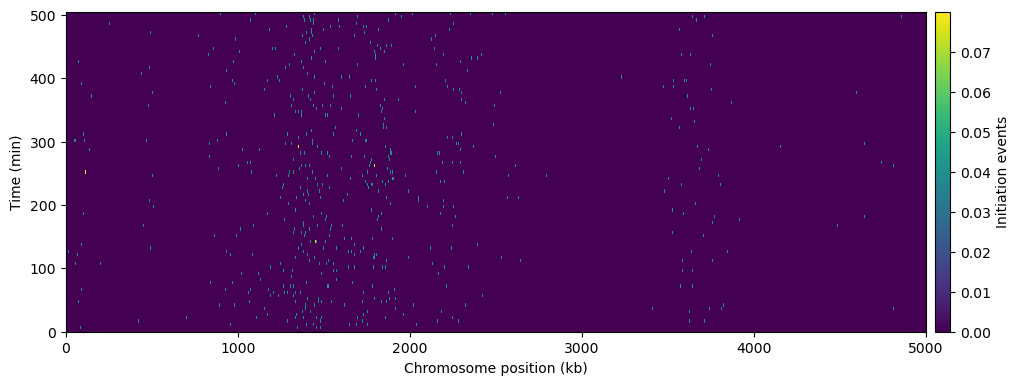

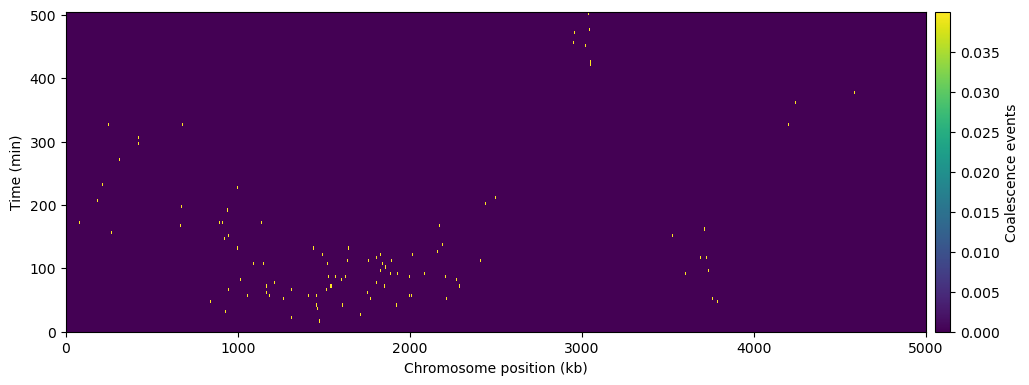

In [30]:
plotf(
    xt_simulation["initiation_events_xt"],
    x_array=showcase_positions_kb,
    time_array=xt_simulation["time_grid"],
    labels=["Initiation events"],
    xtitle="Chromosome position (kb)",
    ytitle="Time (min)",
)

plotf(
    xt_simulation["coalescence_events_xt"],
    x_array=showcase_positions_kb,
    time_array=xt_simulation["time_grid"],
    labels=["Coalescence events"],
    xtitle="Chromosome position (kb)",
    ytitle="Time (min)",
)


### 8.3 Directional and total fork density

`right_fork_density_xt` and `left_fork_density_xt` keep the directional fork-density fields separately. Summing them gives a total fork-density field, while comparing them gives access to directional replication structure.


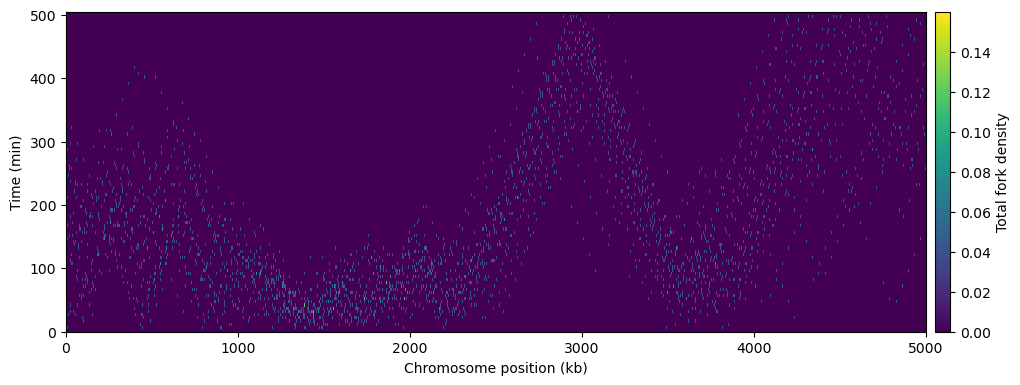

In [31]:
total_fork_density_xt = (
    xt_simulation["right_fork_density_xt"]
    + xt_simulation["left_fork_density_xt"]
)

plotf(
    total_fork_density_xt,
    x_array=showcase_positions_kb,
    time_array=xt_simulation["time_grid"],
    labels=["Total fork density"],
    xtitle="Chromosome position (kb)",
    ytitle="Time (min)",
)


## 9. Optional Mechanisms and `rmap` Routes

The examples above use the default linear geometry with no fork stalling and no finite firing-factor pool. `rsim` can also explore mechanism changes directly:

1. `geometry="periodic"` or `perQ=True` for circular or tiled domains.
2. `stall_rate` and `tau` for transient fork stalling.
3. `ffiring_nr`, `ffiring_recycle` and `ffiring_forkQ` for finite firing-factor dynamics.

The same simulation engine can be reached through `rmap` when a requested target is simulation-derived. This is useful when a notebook or analysis script wants one feature without manually managing the full simulation dictionary.


### 9.1 Stalling and finite firing-factor diagnostics

The default ensemble already returns `stalled_forks`, but without stalling it remains zero. A small mechanism run makes the diagnostic outputs visible: `stall_rate` and `tau` create transiently stalled forks, while `ffiring_nr`, `ffiring_recycle` and `ffiring_forkQ` expose the finite firing-factor pool through `firing_factors`.


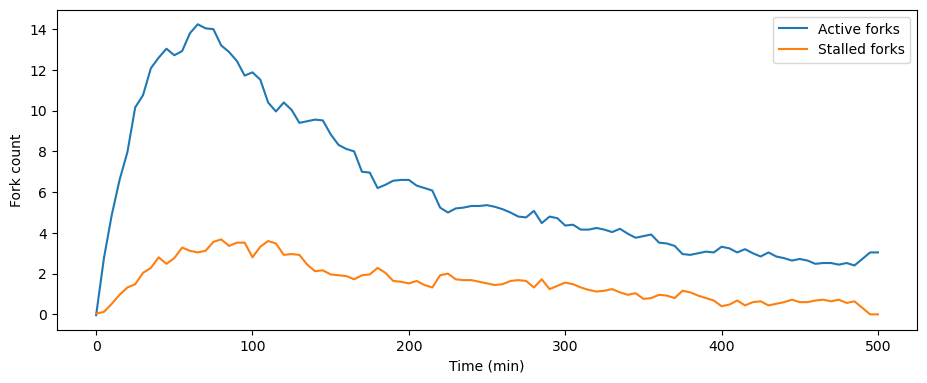

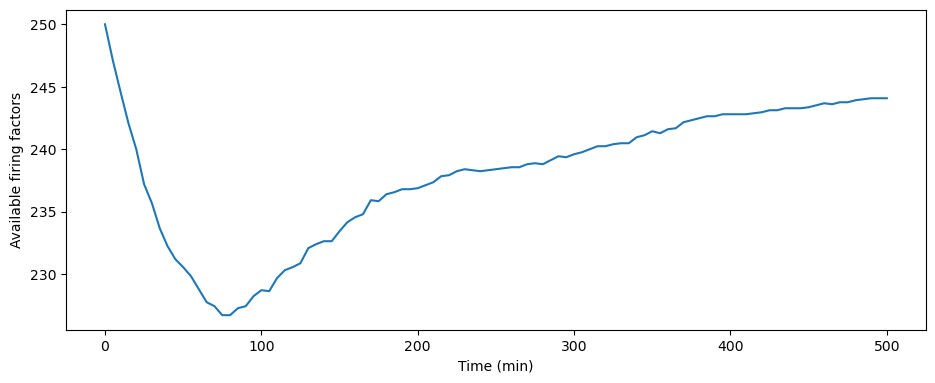

In [32]:
mechanism_simulation = rsim(
    source={
        "firing_rate": showcase_firing_rate,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 25,
        "resolution_x": output_resolution_kb,
        "seed": 4,
        "time_statsQ": True,
        "time_grid": showcase_time_grid,
        "stall_rate": 0.02,
        "tau": 10.0,
        "ffiring_nr": 250,
        "ffiring_recycle": 0.05,
        "ffiring_forkQ": True,
        "verbose": False,
    },
)

plotf(
    mechanism_simulation["active_forks"],
    mechanism_simulation["stalled_forks"],
    x_array=mechanism_simulation["time_grid"],
    labels=["Active forks", "Stalled forks"],
    xtitle="Time (min)",
    ytitle="Fork count",
)

plotf(
    mechanism_simulation["firing_factors"],
    x_array=mechanism_simulation["time_grid"],
    xtitle="Time (min)",
    ytitle="Available firing factors",
)


### 9.2 Request a simulation-derived feature through `rmap`

When only one derived feature is needed, `rmap` can call the simulation route directly. The example below requests `origin_efficiency` from `firing_rate` and `fork_speed` without manually unpacking the full `rsim` dictionary.


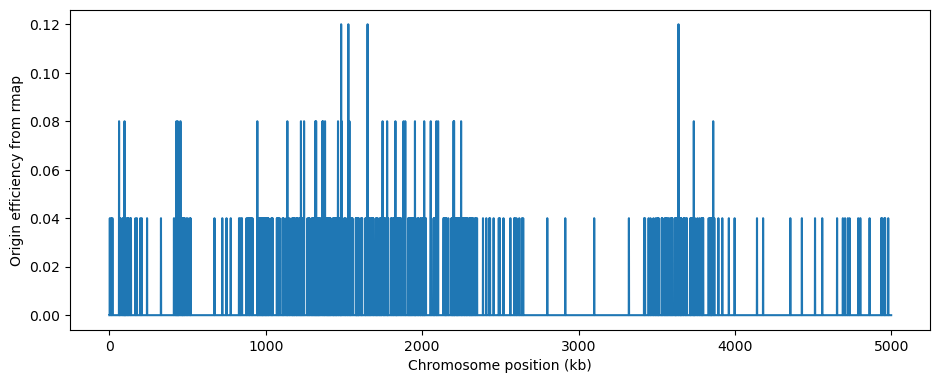

In [33]:
origin_efficiency_from_rmap = rmap(
    source={
        "firing_rate": showcase_firing_rate,
        "fork_speed": fork_speed,
    },
    target="origin_efficiency",
    assumptions={
        "sim_number": 25,
        "resolution_x": output_resolution_kb,
        "seed": 3,
        "verbose": False,
    },
)

plotf(
    origin_efficiency_from_rmap,
    x_array=showcase_positions_kb,
    xtitle="Chromosome position (kb)",
    ytitle="Origin efficiency from rmap",
)
